# The Machine Learning Workflow

**Project:** Home Credit Default Risk  
**Team:**    Maryam Sajedi 
**Date:**    09.11.2026

This notebook covers **Milestone 0 (data ingestion)**. No modelling happens here.

## Define the Business Goal

The stakeholder is a **credit risk manager at Home Credit**, a lender that serves people with little or no credit history. Every day they review many loan applications and must decide which ones to approve, so that the company grows its customer base without losing money on loans that are never repaid.

Estimate whether an applicant will have **repayment difficulties** using only information known *at the time of the application*, so the manager can approve safe applicants quickly, look more closely at risky ones, and avoid rejecting good customers who simply have no credit history.

The decision depends on many attributes at once (income, credit amount, employment, past loans, payment behaviour), so a model gives a faster and more consistent estimate than a manual rule of thumb.

The estimate should be useful in practice: it must rank risky applicants above safe ones, and it must catch enough real defaulters without wrongly turning away too many good customers.

In data science terms this is a **binary classification** problem: the target `TARGET` is 1 (repayment difficulties) or 0 (no difficulties), and the competition measures performance with the **area under the ROC curve (AUC)** of the predicted probabilities.


### Definition of done for this notebook
- All seven tables are loaded without errors.
- For each table I can say what one row represents and which key links it to the others.
- I know how many applicants are in train and test, and what share of them default.
- I know which columns have the most missing values.

## 1. Setup

Import the corresponding libraries needed and set the path to the data folder.

**Hints**
- We will need `pandas`, `numpy` and `matplotlib` and `seaborn`. Add any missing package with `uv add <package>`.
- Keep the data in `data/`. That folder must stay in `.gitignore` because Kaggle data may not be redistributed.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [16]:
from pathlib import Path

# Folder that holds the Kaggle CSV files (must be listed in .gitignore)
DATA_DIR = Path("data/home-credit-default-risk")

# Show more columns and rows when printing DataFrames
pd.set_option("display.max_columns", 130)
pd.set_option("display.max_rows", 100)

# Consistent plot style
sns.set_theme(style="whitegrid")

## Get the Data

We load the Home Credit tables. The main table holds the applicant attributes and the target (`TARGET`), and six side tables hold the credit history of each applicant.

The download has these files:

| File | Content |
|---|---|
| `application_train.csv` | One row per loan application, with the target `TARGET` |
| `application_test.csv` | Same as train, without the target |
| `bureau.csv` | Applicant's loans at other financial institutions |
| `bureau_balance.csv` | Monthly status of those bureau loans |
| `previous_application.csv` | Earlier applications at Home Credit |
| `POS_CASH_balance.csv` | Monthly history of earlier point-of-sale and cash loans |
| `credit_card_balance.csv` | Monthly history of earlier credit cards |
| `installments_payments.csv` | Payment history of earlier loans |
| `HomeCredit_columns_description.csv` | Description of every column |

**Hints**
- Load one table into one variable (for example `app_train`) with `pd.read_csv`.
- The large tables (`installments_payments`, `bureau_balance`) can use a lot of memory. If loading is slow or fails, load only the columns you need with `usecols`, or reduce the dtypes.
- Print the shape of each table after loading it.

In [17]:
app_train = pd.read_csv(DATA_DIR / "application_train.csv")
app_test = pd.read_csv(DATA_DIR / "application_test.csv")

print("app_train:", app_train.shape)
print("app_test: ", app_test.shape)

app_train: (307511, 122)
app_test:  (48744, 121)


In [18]:
bureau = pd.read_csv(DATA_DIR / "bureau.csv")
bureau_balance = pd.read_csv(DATA_DIR / "bureau_balance.csv")
previous_application = pd.read_csv(DATA_DIR / "previous_application.csv")
pos_cash = pd.read_csv(DATA_DIR / "POS_CASH_balance.csv")
credit_card = pd.read_csv(DATA_DIR / "credit_card_balance.csv")
installments = pd.read_csv(DATA_DIR / "installments_payments.csv")

tables = {
    "bureau": bureau,
    "bureau_balance": bureau_balance,
    "previous_application": previous_application,
    "pos_cash": pos_cash,
    "credit_card": credit_card,
    "installments": installments,
}

for name, df in tables.items():
    print(f"{name:22s} {df.shape}")

bureau                 (1716428, 17)
bureau_balance         (27299925, 3)
previous_application   (1670214, 37)
pos_cash               (10001358, 8)
credit_card            (3840312, 23)
installments           (13605401, 8)


## 3. Column descriptions

Open `HomeCredit_columns_description.csv` and read it. You will refer back to it often.

**Hints**
- Load it with `pd.read_csv`. It may need `encoding="latin-1"`.
- Search it for the columns that look important (income, credit amount, age, employment, external scores).

In [22]:
col_desc = pd.read_csv(
    DATA_DIR / "HomeCredit_columns_description.csv",
    encoding="latin-1",
    index_col=0,
)

col_desc = col_desc.reset_index(drop=True)
print(col_desc.shape)
col_desc.tail()

(219, 4)


,Table,Row,Description,Special
214,installments_payments.csv,NUM_INSTALMENT_NUMBER,On which installment we observe payment,NaN
215,installments_payments.csv,DAYS_INSTALMENT,When the installment of previous credit was su...,time only relative to the application
216,installments_payments.csv,DAYS_ENTRY_PAYMENT,When was the installments of previous credit p...,time only relative to the application
217,installments_payments.csv,AMT_INSTALMENT,What was the prescribed installment amount of ...,NaN
218,installments_payments.csv,AMT_PAYMENT,What the client actually paid on previous cred...,NaN


## 4. Inspect the main table: `application_train`

This is the table with the target. Take time here.

**Hints**
- Look at `.shape`, `.head()`, `.dtypes` and `.info()`.
- Count how many columns are numeric and how many are categorical (`object`).
- Check for duplicate rows and for duplicate `SK_ID_CURR` values.

In [20]:
print(app_train.shape)
app_train.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [23]:
# How many columns of each type?
print(app_train.dtypes.value_counts())

# Duplicate rows and duplicate applicant IDs
print("duplicate rows:       ", app_train.duplicated().sum())
print("duplicate SK_ID_CURR: ", app_train["SK_ID_CURR"].duplicated().sum())

# Text columns and how many categories each has
app_train.select_dtypes(exclude="number").nunique().sort_values(ascending=False)

float64    65
int64      41
str        16
Name: count, dtype: int64
duplicate rows:        0
duplicate SK_ID_CURR:  0


ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_INCOME_TYPE               8
NAME_TYPE_SUITE                7
WEEKDAY_APPR_PROCESS_START     7
WALLSMATERIAL_MODE             7
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_EDUCATION_TYPE            5
FONDKAPREMONT_MODE             4
CODE_GENDER                    3
HOUSETYPE_MODE                 3
NAME_CONTRACT_TYPE             2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
dtype: int64

## 5. The target variable

**Questions to answer (in your own words, below the code)**
1. How many applicants have `TARGET` = 0 and how many `TARGET` = 1?
2. What is the percentage of defaults?
3. What does this imbalance mean for the choice of metric and for the baseline?

**Hints**
- Use `value_counts()` with and without `normalize=True`.
- A simple bar chart makes the imbalance easy to see.

In [25]:
# Counts and percentages of each class
print(app_train["TARGET"].value_counts())
print(app_train["TARGET"].value_counts(normalize=True).round(4))

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64


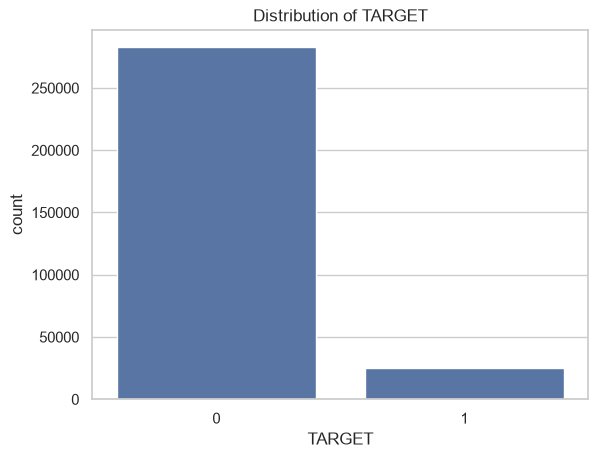

In [26]:
# Bar chart of the two classes
sns.countplot(data=app_train, x="TARGET")
plt.title("Distribution of TARGET")
plt.show()

Why **accuracy** is a trap: a model that predicts “no default” for everyone would be correct 91.9% of the time. That looks excellent, but it would catch none of the 24,825 defaulters, which means it fails the one thing the lender needs. Accuracy rewards the model for ignoring the minority class.

What to use instead:

**AUC (ROC-AUC)**: the competition metric. It measures how well the model ranks defaulters above non-defaulters, and it doesn’t depend on a threshold. The “predict all zeros” baseline scores 0.5, which is a useful reference point.

**Recall**: of the real defaulters, how many do you catch? It matters here because a missed defaulter means a lost loan.

_Write your answers here._

## 6. Inspect the other tables

Repeat the basic checks for each side table. Use the same questions every time.

For each table, answer:
- What does one row represent?
- Which column links it to the applicant (`SK_ID_CURR`, `SK_ID_PREV`, or `SK_ID_BUREAU`)?
- How many rows are there per applicant, on average?
- What are the main data types, and are any date-like columns stored as numbers?

**Hint:** write a small helper function that prints the shape, dtypes, missing values and number of unique keys for a DataFrame. You can then call it on every table.

In [ ]:
# helper function for basic checks

### 6.1 `bureau`

### 6.2 `bureau_balance`

### 6.3 `previous_application`

### 6.4 `POS_CASH_balance`

### 6.5 `credit_card_balance`

### 6.6 `installments_payments`

## 7. Missing values

**Questions to answer**
1. Which columns in `application_train` have the most missing values?
2. Are the missing values spread randomly, or do whole groups of columns (for example housing information) miss together?
3. Are the missing-value patterns similar in `application_test`?

**Hints**
- Compute the percentage of missing values per column and sort it.
- Plot the top 20 columns as a horizontal bar chart.
- Missing does not always mean "unknown". Sometimes it carries information. Do not drop columns yet. That decision belongs to the EDA and modelling milestones.

## 8. How the tables link together

Understanding the keys now will save time when you build features.

**Questions to answer**
1. Which key links `bureau` to `application_train`?
2. Which key links `bureau_balance` to `bureau`?
3. Which key links `POS_CASH_balance`, `credit_card_balance` and `installments_payments` to `previous_application`, and then to the applicant?
4. How many applicants in `application_train` have no rows at all in each side table?

**Hint:** draw the relationships on paper or as a small diagram, then check them with `isin` and `nunique`.

_Write your answers here, or paste a diagram of the table relationships._

## 9. Train and test comparison

**Questions to answer**
1. How many applicants are in train and in test?
2. Do train and test have the same columns (apart from `TARGET`)?
3. Do the main columns have similar distributions in both sets?

**Hint:** compare `.columns` as sets, and compare a few key columns with `describe()`.

## 10. Summary and next steps

Fill this in at the end. It is your hand-in for Milestone 0.

**What I learned about the data**
- _Rows and columns per table_
- _Share of defaults_
- _Columns with the most missing values_
- _How the tables link_

**Problems or surprises**
- _Anything unexpected or unclear_

**Next milestone (EDA, due Day 2, 12:00)**
- _Which questions do I want to answer with visualisations?_

Before committing: clear all notebook outputs, check that `git status` does not show `data/`, and close the Milestone 0 issue on the Kanban board.